# Tracé de courbes à partir d'un fichier `.rpt`

Ce notebook permet de lire un fichier `.rpt` (Abaqus, ANSYS, etc.), d'ignorer automatiquement les en-têtes textuels et de tracer une ou plusieurs courbes avec titre, légendes, grille et gestion des échelles.

## 1. Importation des bibliothèques

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Affichage des graphiques directement dans le notebook
%matplotlib inline

## 2. Fonction de lecture du fichier `.rpt`

Cette fonction parcourt le fichier ligne par ligne, ignore les lignes vides ou textuelles, gère les virgules décimales éventuelles et retourne un tableau NumPy.

In [2]:
def lire_fichier_rpt(chemin_fichier):
    """Lit un fichier .rpt en ignorant automatiquement les en-têtes texte
    et les lignes vides, puis retourne les colonnes numériques.
    """
    donnees = []
    with open(chemin_fichier, "r", encoding="utf-8", errors="ignore") as f:
        for ligne in f:
            ligne = ligne.strip()
            if not ligne:
                continue
            morceaux = ligne.split()
            try:
                valeurs = [float(val.replace(",", ".")) for val in morceaux]
                donnees.append(valeurs)
            except ValueError:
                continue

    if not donnees:
        raise ValueError("Aucune donnée numérique trouvée dans le fichier .rpt.")

    return np.array(donnees)

## 3. Paramètres à personnaliser

Modifiez les valeurs ci-dessous selon votre fichier et l'apparence souhaitée.

In [ ]:
# Chemin vers le fichier .rpt
chemin_rpt = r""

# Titre et noms des axes
titre = "Évolution de la contrainte en fonction du temps"
label_x = "Temps (s)"
label_y = "Contrainte (MPa)"

# Noms des courbes pour la légende (une par colonne Y)
# Laissez None pour une numérotation automatique ("Courbe 1", "Courbe 2"...)
noms_courbes = ["Capteur 1"]

# Échelles : "linear" ou "log"
echelle_x = "linear"
echelle_y = "linear"

# Bornes des axes : (min, max) ou None pour un ajustement automatique
limites_x = None  # Exemple : (0, 10)
limites_y = None  # Exemple : (0, 500)

# Nom du fichier image exporté
fichier_sortie = "courbe_rpt.png"

## 4. Chargement et vérification des données

In [11]:
data = lire_fichier_rpt(chemin_rpt)
x = data[:, 0]         # Première colonne = abscisses (X)
colonnes_y = data[:, 1:]  # Colonnes suivantes = ordonnées (Y)

print(f"Données chargées : {data.shape[0]} lignes, {data.shape[1]} colonnes")
print("Aperçu des 5 premières lignes :")
print(data[:5])

Données chargées : 104 lignes, 2 colonnes
Aperçu des 5 premières lignes :
[[0.        0.       ]
 [0.0993418 0.       ]
 [0.198662  0.       ]
 [0.298003  0.       ]
 [0.397323  0.       ]]


## 5. Tracé et export de la courbe

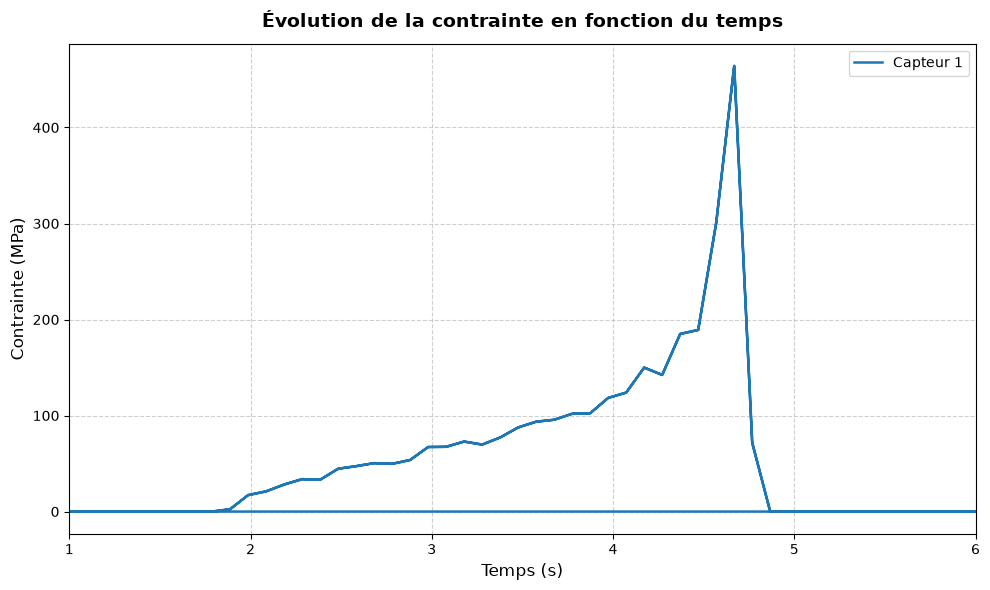

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

for i in range(colonnes_y.shape[1]):
    label = (
        noms_courbes[i]
        if noms_courbes and i < len(noms_courbes)
        else f"Courbe {i + 1}"
    )
    ax.plot(x, colonnes_y[:, i], linewidth=1.8, label=label)

# Titre et noms des axes
ax.set_title(titre, fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel(label_x, fontsize=12)
ax.set_ylabel(label_y, fontsize=12)

# Échelles et bornes
ax.set_xscale(echelle_x)
ax.set_yscale(echelle_y)
if limites_x:
    ax.set_xlim(limites_x)
if limites_y:
    ax.set_ylim(limites_y)

# Grille et légende
ax.grid(True, which="both", linestyle="--", alpha=0.6)
ax.legend(loc="best", frameon=True)

plt.tight_layout()
plt.savefig(fichier_sortie, dpi=300)
plt.show()